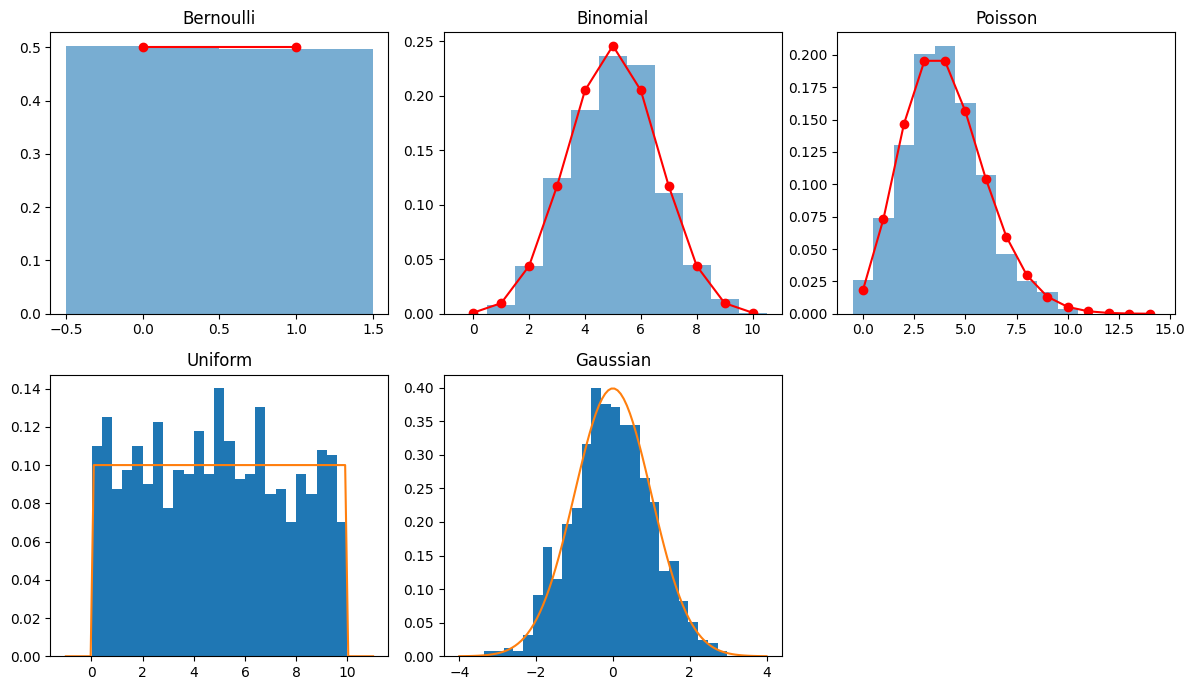

Probability of Disease given Positive: 8.76 %
Empirical Probability: 8.84 %


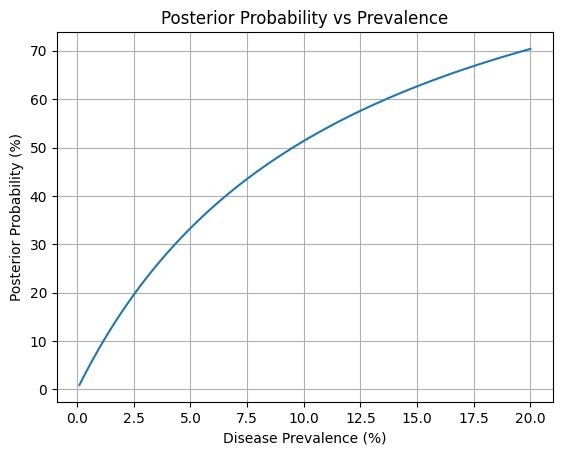

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bernoulli, binom, poisson, uniform, norm

np.random.seed(42)

# 1. Generate Probability Distributions
n = 1000

samples = {
    "Bernoulli": bernoulli.rvs(0.5, size=n),
    "Binomial": binom.rvs(10, 0.5, size=n),
    "Poisson": poisson.rvs(4, size=n),
    "Uniform": uniform.rvs(0, 10, size=n),
    "Gaussian": norm.rvs(0, 1, size=n)
}

# 2. Plot Distributions
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

distributions = [
    (bernoulli(0.5), np.arange(2), "Bernoulli"),
    (binom(10, 0.5), np.arange(11), "Binomial"),
    (poisson(4), np.arange(15), "Poisson")
]

for ax, (dist, x, title) in zip(axes.flat, distributions):
    ax.hist(samples[title], bins=np.arange(x.min()-0.5,
            x.max()+1.5), density=True, alpha=0.6)
    ax.plot(x, dist.pmf(x), 'ro-')
    ax.set_title(title)

x = np.linspace(-1, 11, 100)
axes[1, 0].hist(samples["Uniform"], bins=25, density=True)
axes[1, 0].plot(x, uniform.pdf(x, 0, 10))
axes[1, 0].set_title("Uniform")

x = np.linspace(-4, 4, 100)
axes[1, 1].hist(samples["Gaussian"], bins=25, density=True)
axes[1, 1].plot(x, norm.pdf(x))
axes[1, 1].set_title("Gaussian")

axes[1, 2].axis("off")
plt.tight_layout()
plt.show()

# 3. Bayes' Theorem
P_D = 0.01
sensitivity = 0.95
specificity = 0.90

P_Pos_D = sensitivity
P_Pos_NotD = 1 - specificity

P_Pos = P_Pos_D * P_D + P_Pos_NotD * (1-P_D)

posterior = P_Pos_D * P_D / P_Pos

print("Probability of Disease given Positive:",
      round(posterior * 100, 2), "%")

# 4. Simulate 100,000 Patients
N = 100000

disease = np.random.rand(N) < P_D
positive = np.where(
    disease,
    np.random.rand(N) < sensitivity,
    np.random.rand(N) < P_Pos_NotD
)

empirical = np.sum(disease & positive) / np.sum(positive)

print("Empirical Probability:",
      round(empirical * 100, 2), "%")

# 5. Posterior vs Prevalence
prevalence = np.linspace(0.001, 0.20, 100)

posterior_values = (
    sensitivity * prevalence /
    (sensitivity * prevalence +
     P_Pos_NotD * (1-prevalence))
)

plt.plot(prevalence*100, posterior_values*100)
plt.xlabel("Disease Prevalence (%)")
plt.ylabel("Posterior Probability (%)")
plt.title("Posterior Probability vs Prevalence")
plt.grid()
plt.show()
